# IIR Filter -Zero Pole Placement Method for Notch Filter

<font color="blue">Note: In order to run this Jupyter Notebook you must create a file named `digital_filters.py` inside the folder containing this Notebook with the following functions `filter_frequency_response` and `zeros_poles_gain` which were developed previously.</font> 

A **notch filter** rejects a narrow frequency band and leaves the rest of the spectrum little changed. The most common example is 60-Hz noise from power lines. Another is low-frequency ground roll. Such filters can easily be made using a slight variation on the all-pass filter. In the all-pass filter, the pole and zero have equal (logarithmic) relative distances from the unit circle. All we need to do is **put the zero closer to the circle**. Indeed, there is no reason why we should not put the zero right on the circle: then the frequency at which the zero is located is exactly canceled from the spectrum of input data.

Narrow-band filters and sharp cutoff filters should be used with caution. An ever-present penalty for using such filters is that they do not decay rapidly in time. Although this may not present problems in some applications, it will certainly do so in others. 

![Notch Filter](Images/notch_filter.png)

## Algorithm for Designing a Notch Filter

In order to design a notch filter using the zero pole placement method we perform the following steps:
1. Set a zero near the unit circle at the frequency of interest.
2. Find the complex conjugate of the zero obtained in step 1.
3. Set a pole and it's conjugate near the unit circle at the frequency of interest. To maintain stability, the zero should be closest to the unit circle than the pole's location.
4. Merge zeros and poles in a transfer function.
5. Adjust the zeros and poles to your needs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

from aux_plots import plot_zeros_poles
from digital_filters import filter_frequency_response, zeros_poles_gain

## Implementation:
### Step 1: Set a zero near the unit circle at the frequency of interest. 

In this case we will define a transfer function $H_1(z)$ with a zero
$$ H_1(z)=1-b z^{-1} $$

where $b$ is a complex constant with a radius $r$ and phase angle $\phi$ radians:
$$ b=r e^{j \phi}$$


To implement this in our code, we need to change the transfer function $H_1(z)$ into our coding style. Remember that the format our transfer function has is the following:

$$H[z] = \frac{c_0 + c_1z + c_2z^{2} + c_3z^{3} + \cdot \cdot \cdot}{d_0 + d_1z + d_2z^{2} + d_3z^{3}+ \cdot \cdot \cdot} $$

Therefore, rewriting our transfer function $H_1(z)$ becomes:

$$ H_1(z) = \frac{-b+z}{z}$$

We now can implement a transfer function $H_1(z)$ with a radius close to the unit circle, i.e. $r=0.9$ and a value of $\phi = \pi/4$ radians.

In [2]:
# Set the values of r_zero to 0.9, phi as pi/4, and find b
### BEGIN SOLUTION
r_zero = 0.9
phi = np.pi/4
b = r_zero*np.exp(1j*phi)
### END SOLUTION

# Create an array c which consist of the numerator coefficients of 
# the transfer function H1(z) described above.
### BEGIN SOLUTION
c = np.array([-b,1])
### END SOLUTION

# Create an array d which consist of the denominator coefficients of 
# the transfer function H1(z) described above.
### BEGIN SOLUTION
d = np.array([0, 1])
### END SOLUTION

# Create an array w with a range between 0 and 2*pi and a step size of 0.01
# This range allow us to see the symmetry of the filter.
### BEGIN SOLUTION
w = np.arange(0, 2*np.pi, 0.01)
### END SOLUTION

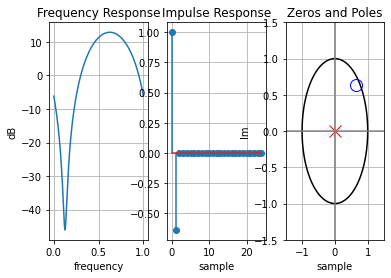

In [3]:
H_w = filter_frequency_response(c,d,w)
idft = np.fft.ifft(H_w)
z, p, g = zeros_poles_gain(c, d)

with open('zero_pole_step_1.pkl', 'rb') as file:
    H_w_pkl, idft_pkl, (z_pkl, p_pkl, g_pkl) = pickle.load(file)

assert np.isclose(H_w_pkl, H_w, atol=0.01).all()
assert np.isclose(idft_pkl, idft, atol=0.01).all()
assert np.isclose(z_pkl, z, atol=0.01).all()
assert np.isclose(p_pkl, p, atol=0.01).all()
assert np.isclose(g_pkl, g, atol=0.01).all()


plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1, 3, 1)
plt.plot(w/(max(w)), 20*np.log(np.absolute(H_w)))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

plt.subplot(1, 3, 2)
plt.stem(np.real(idft[0:25]), use_line_collection=True)
plt.title('Impulse Response')
plt.xlabel('sample')
plt.grid('on')

plot_zeros_poles(z, p)
plt.title('Zeros and Poles')
plt.xlabel('sample')
plt.show()

### Step 2: Find the complex conjugate of the zero obtained in step 1.
Now we will expand our transfer function, and obtain $H_2(z)$. This transfer function has two zeros, one is the previous one obtained in step 1 and the other is it's conjugate.

$$H_2(z) = (1-b z^{-1})(1-b^* z^{-1})$$

To be able to use it, we perform some manipulations to get $H_2(z)$ into our coding style, therefore we get:

$$H_2(z) = \frac{bb^*-(b+b^*)z+z^2}{z^2}$$



In [4]:
# Set the values of r_zero to 0.9, phi as pi/4, and find b
### BEGIN SOLUTION
r_zero = 0.9
phi = np.pi/4
b = r_zero*np.exp(1j*phi)
### END SOLUTION

# Create an array c which consist of the numerator coefficients of 
# the transfer function H2(z) described above.
### BEGIN SOLUTION
c = np.array([b*np.conj(b),-(b+np.conj(b)), 1])
### END SOLUTION

# Create an array d which consist of the denominator coefficients of 
# the transfer function H2(z) described above.
### BEGIN SOLUTION
d = np.array([0, 0, 1])
### END SOLUTION

# Create an array w with a range between 0 and 2*pi and a step size of 0.01
# This range allow us to see the symmetry of the filter.
### BEGIN SOLUTION
w = np.arange(0, 2*np.pi, 0.01)
### END SOLUTION

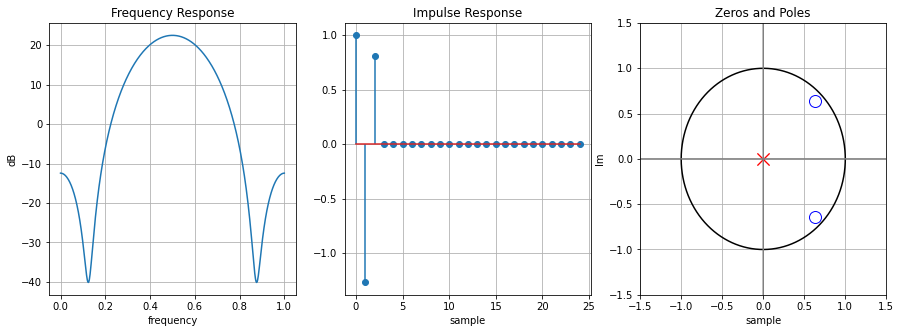

In [5]:
H_w = filter_frequency_response(c,d,w)
idft = np.fft.ifft(H_w)
z, p, g = zeros_poles_gain(c, d)

with open('zero_pole_step_2.pkl', 'rb') as file:
    H_w_pkl, idft_pkl, (z_pkl, p_pkl, g_pkl) = pickle.load(file)

assert np.isclose(H_w_pkl, H_w, atol=0.01).all()
assert np.isclose(idft_pkl, idft, atol=0.01).all()
assert np.isclose(z_pkl, z, atol=0.01).all()
assert np.isclose(p_pkl, p, atol=0.01).all()
assert np.isclose(g_pkl, g, atol=0.01).all()

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1, 3, 1)
plt.plot(w/(max(w)), 20*np.log(np.absolute(H_w)))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

plt.subplot(1, 3, 2)
plt.stem(np.real(idft[0:25]), use_line_collection=True)
plt.title('Impulse Response')
plt.xlabel('sample')
plt.grid('on')

plot_zeros_poles(z, p)
plt.title('Zeros and Poles')
plt.xlabel('sample');

### Step 3: Set a pole and it's conjugate near the unit circle at the frequency of interest.
We now proceed to create a transfer function with a pole near the unit circle. To avoid instability, we make the radius of the pole smaller than the zero.

The transfer function is
$$ H_3(z) = \frac{1}{(1-az^{-1})(1-a^*z^{-1})}$$

<br>
Again we perform some manipulations to get $H_3(z)$ into our coding style, and we get:


$$ H_3(z) = \frac{z^2}{aa^*-(a+a^*)z+z^2}$$

In [6]:
# Set the values of r_pole to 0.85, phi as pi/4, and find a
### BEGIN SOLUTION
r_pole = 0.85
phi = np.pi/4
a = r_pole*np.exp(1j*phi)
### END SOLUTION

# Create an array c which consist of the numerator coefficients of 
# the transfer function H3(z) described above.
### BEGIN SOLUTION
c = np.array([0, 0, 1])
### END SOLUTION

# Create an array d which consist of the denominator coefficients of 
# the transfer function H3(z) described above.
### BEGIN SOLUTION
d = np.array([a*np.conj(a),-(a+np.conj(a)), 1])
### END SOLUTION

# Create an array w with a range between 0 and 2*pi and a step size of 0.01
# This range allow us to see the symmetry of the filter.
### BEGIN SOLUTION
w = np.arange(0, 2*np.pi, 0.01)
### END SOLUTION

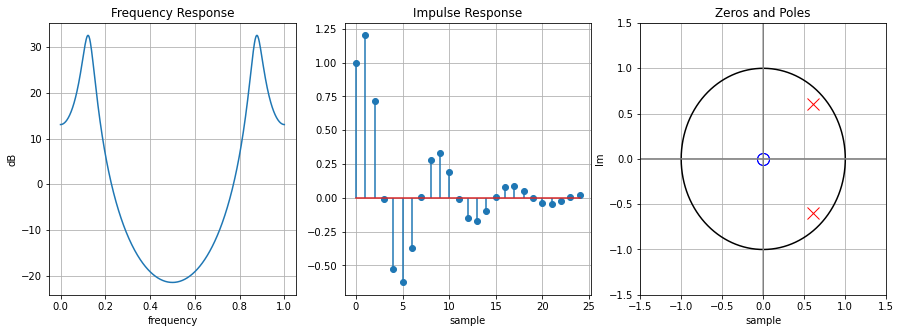

In [7]:
H_w = filter_frequency_response(c,d,w)
idft = np.fft.ifft(H_w)
z, p, g = zeros_poles_gain(c, d)

with open('zero_pole_step_3.pkl', 'rb') as file:
    H_w_pkl, idft_pkl, (z_pkl, p_pkl, g_pkl) = pickle.load(file)

assert np.isclose(H_w_pkl, H_w, atol=0.01).all()
assert np.isclose(idft_pkl, idft, atol=0.01).all()
assert np.isclose(z_pkl, z, atol=0.01).all()
assert np.isclose(p_pkl, p, atol=0.01).all()
assert np.isclose(g_pkl, g, atol=0.01).all()


plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1, 3, 1)
plt.plot(w/(max(w)), 20*np.log(np.absolute(H_w)))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

plt.subplot(1, 3, 2)
plt.stem(np.real(idft[0:25]), use_line_collection=True)
plt.title('Impulse Response')
plt.xlabel('sample')
plt.grid('on')

plot_zeros_poles(z, p)
plt.title('Zeros and Poles')
plt.xlabel('sample');

### Step 4: Merge zeros and poles in a transfer function.
Finally you can combine transfer functions $H_2(z)$ and $H_3(z)$ in a single transfer function

$$H(z) = H_2(z)H_3(z)$$

$$H(z) = \left(\frac{bb^*-(b+b^*)z+z^2}{z^2} \right) \left(\frac{z^2}{aa^*-(a+a^*)z+z^2}\right)$$

Therefore we get
$$H(z) = \frac{bb^*-(b+b^*)z+z^2}{aa^*-(a+a^*)z+z^2}$$

which is the desired form for our transfer function.

In [8]:
# Set the values of r_zero to 0.90, r_pole to 0.85, phi as pi/4, then find a and b
### BEGIN SOLUTION
r_zero = 0.9
r_pole = 0.85

phi = np.pi/4
b = r_zero*np.exp(1j*phi)
a = r_pole*np.exp(1j*phi)
### END SOLUTION

# Create an array c which consist of the numerator coefficients of 
# the transfer function H(z) described above.
### BEGIN SOLUTION
c = np.array([b*np.conj(b),-(b+np.conj(b)), 1])
### END SOLUTION

# Create an array d which consist of the denominator coefficients of 
# the transfer function H(z) described above.
### BEGIN SOLUTION
d = np.array([a*np.conj(a),-(a+np.conj(a)), 1])
### END SOLUTION

# Create an array w with a range between 0 and 2*pi and a step size of 0.01
# This range allow us to see the symmetry of the filter.
### BEGIN SOLUTION
w = np.arange(0, 2*np.pi, 0.01)
### END SOLUTION

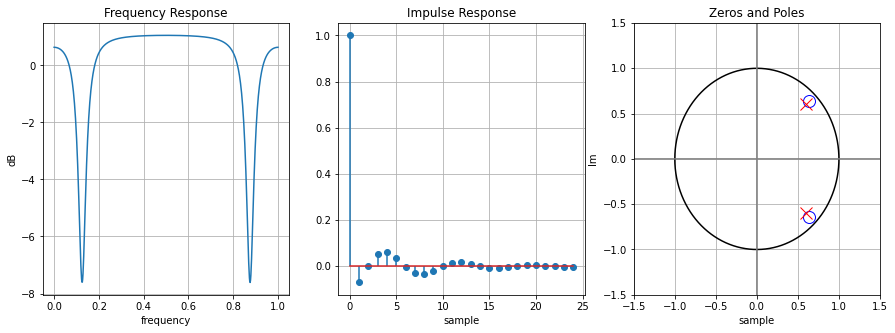

In [9]:
H_w = filter_frequency_response(c,d,w)
idft = np.fft.ifft(H_w)
z, p, g = zeros_poles_gain(c, d)

with open('zero_pole_step_4.pkl', 'rb') as file:
    H_w_pkl, idft_pkl, (z_pkl, p_pkl, g_pkl) = pickle.load(file)

assert np.isclose(H_w_pkl, H_w, atol=0.01).all()
assert np.isclose(idft_pkl, idft, atol=0.01).all()
assert np.isclose(z_pkl, z, atol=0.01).all()
assert np.isclose(p_pkl, p, atol=0.01).all()
assert np.isclose(g_pkl, g, atol=0.01).all()

plt.rcParams["figure.figsize"] = (15,5)

plt.subplot(1, 3, 1)
plt.plot(w/(max(w)), 20*np.log(np.absolute(H_w)))
plt.title('Frequency Response')
plt.xlabel('frequency')
plt.ylabel('dB')
plt.grid('on')

plt.subplot(1, 3, 2)
plt.stem(np.real(idft[0:25]), use_line_collection=True)
plt.title('Impulse Response')
plt.xlabel('sample')
plt.grid('on')

plot_zeros_poles(z, p)
plt.title('Zeros and Poles')
plt.xlabel('sample');

#### Reference
* https://dsp.stackexchange.com/questions/41642/filter-design-with-zero-pole-placement-method
* http://sepwww.stanford.edu/sep/prof/pvi/zp/paper_html/node30.html